# Gaussian Process sound-field simulation

This notebook runs **my GP workflow only** across Andrei's three synthetic sound fields: one stationary point source, three stationary point sources, and one moving point source.

It runs the sampling, GP prediction and evaluation Python files in order. Each scene uses 5, 10, 20, 50 and 100 phones with random, grid and clustered layouts, giving **45 GP runs**. All observation arrays, prediction arrays and numerical scores are saved. The figures are:

1. Three separate 100-grid-phone sampling maps, one for each scene.
2. One **3 × 3** figure: true field, GP prediction and absolute error for each of the three scenes.
3. One line figure comparing GP RMSE across the three scenes, five phone counts and three layouts.

The sampling and nine-panel map figures use **frame 0**. Run the cells from top to bottom, or use **Run All**. Keep the `austin` and `andreib` folders together. The moving scene is fitted separately at each of its 101 frames; this is a sequence of spatial GPs rather than a temporal GP.


## 1. Locate the GP files

The notebook can be launched from the MDM3 folder, the simulation folder, or the `austin` folder. It uses NumPy, Matplotlib and IPython. The Python files remain the source of the calculations, so any later GP changes need to be made in those files.


In [1]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import csv
import sys

import numpy as np
import matplotlib
matplotlib.use('Agg')
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
candidates = [candidate for folder in (current, *current.parents)
              for candidate in (folder, folder / '仿真' / 'austin')]
AUSTIN = next((candidate for candidate in candidates
               if (candidate / 'gp_all_sources_sampling.py').is_file()
               and (candidate / 'gp_all_sources_model.py').is_file()
               and (candidate / 'gp_all_sources_test.py').is_file()), None)
if AUSTIN is None:
    raise FileNotFoundError('Cannot find the three GP Python files. Open from the MDM3 project folder.')
if not (AUSTIN.parent / 'andreib' / 'extract_sound.py').is_file():
    raise FileNotFoundError('Keep the adjacent andreib folder with the GP files.')
sys.path.insert(0, str(AUSTIN))
DATA = AUSTIN / 'gp_all_sources_output'
INPUTS = DATA / 'model_inputs'
PREDICTIONS = DATA / 'gp_predictions'
EVALUATION = DATA / 'evaluation_only'
SCENARIOS = ('single_static', 'multiple_static', 'single_moving')
print('GP code folder:', AUSTIN)
print('Result folder:', DATA)


GP code folder: /Users/a603/Desktop/MDM3/仿真/austin
Result folder: /Users/a603/Desktop/MDM3/仿真/austin/gp_all_sources_output


## 2. Prepare the simulated phone readings

The sampler calls Andrei's existing scene and sampling code. It saves the phone coordinates and measured levels in `model_inputs`. Complete true maps and known source positions go to `evaluation_only` for later scoring. The GP model does not read them.


In [2]:
from gp_all_sources_sampling import main as prepare_gp_samples

with redirect_stdout(StringIO()):
    prepare_gp_samples()
with (DATA / 'sampling_manifest.csv').open(newline='') as file:
    sampling_runs = list(csv.DictReader(file))
if len(sampling_runs) != 45:
    raise ValueError(f'Expected 45 sampling configurations, found {len(sampling_runs)}')
print(f'Prepared {len(sampling_runs)} sampling configurations across 3 scenes.')
for scene in SCENARIOS:
    with np.load(INPUTS / scene / 'observations_100_grid.npz', allow_pickle=False) as sample:
        print(f"{scene}: phone positions {sample['phone_positions'].shape}, "
              f"phone levels {sample['phone_levels'].shape}")


Prepared 45 sampling configurations across 3 scenes.
single_static: phone positions (100, 2), phone levels (1, 100)
multiple_static: phone positions (100, 2), phone levels (1, 100)
single_moving: phone positions (100, 2), phone levels (101, 100)


**Output explained:** `phone_positions` contains the 100 example coordinates. `phone_levels` has one row per time frame: one row for each stationary scene and 101 rows for the moving scene. All other phone counts and layouts were also prepared.


## 3. Run the GP prediction

This calls the existing RBF GP model for all 45 configurations. Its inputs are only `phone_positions`, `phone_levels` and `query_positions`; it returns a predicted sound-level map for every frame. The current model uses a fixed 15 m length scale, 15 dB signal standard deviation and an **assumed** 0.5 dB observation-noise standard deviation. It saves prediction means, not GP uncertainty maps.


In [3]:
from gp_all_sources_model import main as run_gp_model

with redirect_stdout(StringIO()):
    run_gp_model()
with (PREDICTIONS / 'run_manifest.csv').open(newline='') as file:
    gp_runs = list(csv.DictReader(file))
if len(gp_runs) != 45:
    raise ValueError(f'Expected 45 GP predictions, found {len(gp_runs)}')
print(f'Saved {len(gp_runs)} GP prediction arrays.')
for scene in SCENARIOS:
    prediction = np.load(PREDICTIONS / scene / 'prediction_100_grid.npy', mmap_mode='r')
    print(f'{scene}: example prediction shape {prediction.shape}')


Saved 45 GP prediction arrays.
single_static: example prediction shape (1, 40401)
multiple_static: example prediction shape (1, 40401)
single_moving: example prediction shape (101, 40401)


**Output explained:** each prediction has shape `(T, 40401)`, where `T` is the number of frames and 40,401 is the 201 × 201 map grid. The moving-source predictions are independent spatial GP maps for all 101 frames.


## 4. Evaluate all GP predictions

The evaluator now opens the hidden true maps. It scores **all 45 configurations and all frames**, then saves overall, per-frame and near-source tables. The table below shows **every overall score**, while the CSV files retain all per-frame and per-source rows. These are simulated-map errors, not real-phone accuracy results.


In [4]:
from gp_all_sources_test import main as evaluate_gp

with redirect_stdout(StringIO()):
    evaluate_gp()
with (EVALUATION / 'overall_metrics.csv').open(newline='') as file:
    scores = list(csv.DictReader(file))
if len(scores) != 45:
    raise ValueError(f'Expected 45 GP scores, found {len(scores)}')

head = ('| Scene | Phones | Layout | Frames | RMSE | MAE | Bias | P95 abs. error | '
        'Mean peak gap | Mean source MAE | Worst source MAE |')
lines = [head, '|---|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|']
for row in scores:
    lines.append(
        f"| {row['scenario']} | {row['phone_count']} | {row['layout']} | {row['frames']} | "
        f"{float(row['RMSE_db']):.2f} | {float(row['MAE_db']):.2f} | "
        f"{float(row['Bias_db']):.2f} | {float(row['P95_absolute_error_db']):.2f} | "
        f"{float(row['mean_global_peak_gap_db']):.2f} | "
        f"{float(row['mean_source_MAE_db']):.2f} | "
        f"{float(row['worst_source_MAE_db']):.2f} |"
    )
display(Markdown('\n'.join(lines)))
print(f'All {len(scores)} overall rows are displayed above and saved in overall_metrics.csv.')
print('Complete frame and source scores are saved in frame_metrics.csv and per_source_metrics.csv.')


All 45 overall rows are displayed above and saved in overall_metrics.csv.
Complete frame and source scores are saved in frame_metrics.csv and per_source_metrics.csv.


| Scene | Phones | Layout | Frames | RMSE | MAE | Bias | P95 abs. error | Mean peak gap | Mean source MAE | Worst source MAE |
|---|---:|---|---:|---:|---:|---:|---:|---:|---:|---:|
| single_static | 5 | random | 1 | 4.32 | 2.85 | -1.14 | 9.42 | -28.52 | 21.62 | 21.62 |
| single_static | 10 | random | 1 | 2.71 | 1.71 | -0.09 | 5.16 | -22.78 | 15.25 | 15.25 |
| single_static | 20 | random | 1 | 1.57 | 1.03 | 0.58 | 3.37 | -15.41 | 6.51 | 6.51 |
| single_static | 50 | random | 1 | 1.12 | 0.70 | 0.27 | 2.37 | -12.97 | 4.08 | 4.08 |
| single_static | 100 | random | 1 | 0.81 | 0.46 | 0.06 | 1.79 | -10.80 | 2.66 | 2.66 |
| single_static | 5 | grid | 1 | 3.96 | 2.92 | 0.26 | 7.32 | -27.94 | 19.46 | 19.46 |
| single_static | 10 | grid | 1 | 2.14 | 1.44 | 0.79 | 4.42 | -20.25 | 10.61 | 10.61 |
| single_static | 20 | grid | 1 | 1.46 | 0.84 | 0.12 | 2.22 | -20.27 | 10.62 | 10.62 |
| single_static | 50 | grid | 1 | 1.22 | 0.61 | 0.34 | 3.12 | -13.94 | 4.84 | 4.84 |
| single_static | 100 | grid | 1 | 0.59 | 0.18 | 0.00 | 0.58 | -14.25 | 5.17 | 5.17 |
| single_static | 5 | clustered | 1 | 4.78 | 4.09 | 3.28 | 7.84 | -22.48 | 13.64 | 13.64 |
| single_static | 10 | clustered | 1 | 4.19 | 3.57 | 3.43 | 7.20 | -15.76 | 6.46 | 6.46 |
| single_static | 20 | clustered | 1 | 3.81 | 3.05 | 2.48 | 6.76 | -20.56 | 11.45 | 11.45 |
| single_static | 50 | clustered | 1 | 3.30 | 2.57 | 1.97 | 6.03 | -20.26 | 11.08 | 11.08 |
| single_static | 100 | clustered | 1 | 3.10 | 2.24 | 1.89 | 6.07 | -18.64 | 9.25 | 9.25 |
| multiple_static | 5 | random | 1 | 4.39 | 3.15 | -0.21 | 8.59 | -25.73 | 10.68 | 20.64 |
| multiple_static | 10 | random | 1 | 2.86 | 1.90 | 0.91 | 6.52 | -17.34 | 7.33 | 9.84 |
| multiple_static | 20 | random | 1 | 1.87 | 1.15 | 0.29 | 3.65 | -15.57 | 6.58 | 9.45 |
| multiple_static | 50 | random | 1 | 2.20 | 1.40 | -0.43 | 4.71 | -10.77 | 5.00 | 9.80 |
| multiple_static | 100 | random | 1 | 1.39 | 0.65 | -0.17 | 2.52 | -14.29 | 4.25 | 5.87 |
| multiple_static | 5 | grid | 1 | 3.85 | 2.76 | 0.39 | 7.19 | -22.99 | 9.05 | 19.30 |
| multiple_static | 10 | grid | 1 | 2.10 | 1.44 | 0.56 | 3.67 | -17.40 | 7.33 | 8.76 |
| multiple_static | 20 | grid | 1 | 1.76 | 0.97 | 0.06 | 3.20 | -20.31 | 7.08 | 10.68 |
| multiple_static | 50 | grid | 1 | 2.58 | 1.65 | 0.85 | 6.05 | -4.15 | 4.85 | 5.70 |
| multiple_static | 100 | grid | 1 | 0.88 | 0.29 | -0.04 | 0.70 | -14.26 | 4.36 | 5.17 |
| multiple_static | 5 | clustered | 1 | 9.53 | 8.61 | 8.40 | 14.40 | -14.41 | 4.96 | 6.91 |
| multiple_static | 10 | clustered | 1 | 8.54 | 7.11 | 6.80 | 14.16 | -14.10 | 3.81 | 4.93 |
| multiple_static | 20 | clustered | 1 | 16.91 | 14.54 | 8.91 | 29.79 | 2.59 | 13.03 | 24.42 |
| multiple_static | 50 | clustered | 1 | 9.55 | 7.92 | 5.65 | 14.97 | -6.26 | 7.67 | 17.58 |
| multiple_static | 100 | clustered | 1 | 9.40 | 7.41 | 3.69 | 15.25 | -10.08 | 4.03 | 6.13 |
| single_moving | 5 | random | 101 | 4.58 | 3.09 | -0.23 | 9.68 | -26.11 | 19.47 | 26.71 |
| single_moving | 10 | random | 101 | 3.89 | 2.24 | -0.37 | 8.32 | -24.88 | 17.90 | 26.95 |
| single_moving | 20 | random | 101 | 1.94 | 1.16 | 0.51 | 3.86 | -14.17 | 6.62 | 11.84 |
| single_moving | 50 | random | 101 | 2.02 | 0.93 | 0.06 | 3.67 | -10.81 | 4.45 | 8.06 |
| single_moving | 100 | random | 101 | 1.00 | 0.35 | 0.04 | 1.41 | -12.55 | 4.78 | 7.78 |
| single_moving | 5 | grid | 101 | 4.27 | 2.92 | 0.25 | 8.60 | -25.12 | 18.19 | 26.85 |
| single_moving | 10 | grid | 101 | 3.45 | 1.99 | 0.14 | 7.41 | -22.42 | 14.88 | 26.82 |
| single_moving | 20 | grid | 101 | 1.43 | 0.80 | 0.19 | 2.49 | -17.12 | 8.47 | 11.52 |
| single_moving | 50 | grid | 101 | 1.23 | 0.56 | 0.18 | 2.69 | -13.64 | 5.36 | 13.91 |
| single_moving | 100 | grid | 101 | 0.75 | 0.27 | 0.03 | 1.06 | -10.57 | 3.85 | 5.23 |
| single_moving | 5 | clustered | 101 | 5.31 | 3.99 | 1.23 | 9.80 | -26.55 | 18.81 | 27.39 |
| single_moving | 10 | clustered | 101 | 5.09 | 3.71 | 1.03 | 9.46 | -25.75 | 17.92 | 27.58 |
| single_moving | 20 | clustered | 101 | 4.88 | 3.40 | 1.07 | 9.46 | -24.10 | 16.27 | 27.75 |
| single_moving | 50 | clustered | 101 | 4.60 | 3.10 | 0.60 | 8.91 | -24.33 | 16.58 | 27.73 |
| single_moving | 100 | clustered | 101 | 4.64 | 3.03 | 1.05 | 9.20 | -20.27 | 13.51 | 27.64 |

**Output explained:** RMSE and MAE measure whole-map error over every frame. P95 is the 95th percentile of absolute error. Source MAE focuses on points within 5 m of a known source. The moving-source overall metrics include all 101 frames. For the complete numerical precision and all per-frame/source data, use the CSV files in `evaluation_only`.


## 5. Three 100-grid-phone sampling maps

Each image shows the **actual 100 simulated phone readings** at frame 0. Dot position is the phone position; dot colour is its observed sound level. There is one image for each sound field. The other phone counts and layouts are retained as saved arrays and scores.


single_static: 100 grid phones, frame 0
multiple_static: 100 grid phones, frame 0
single_moving: 100 grid phones, frame 0


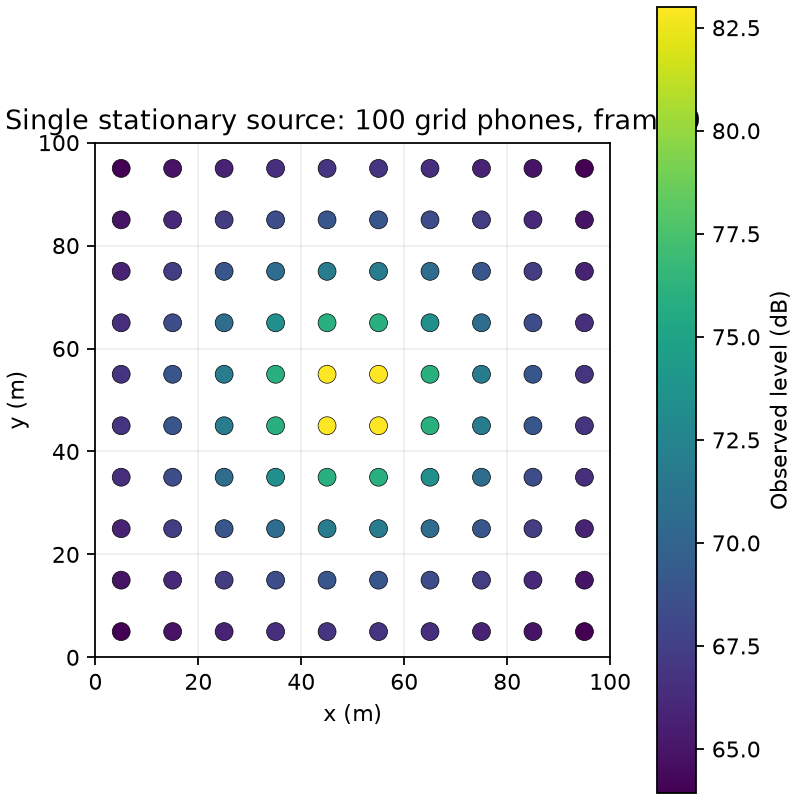

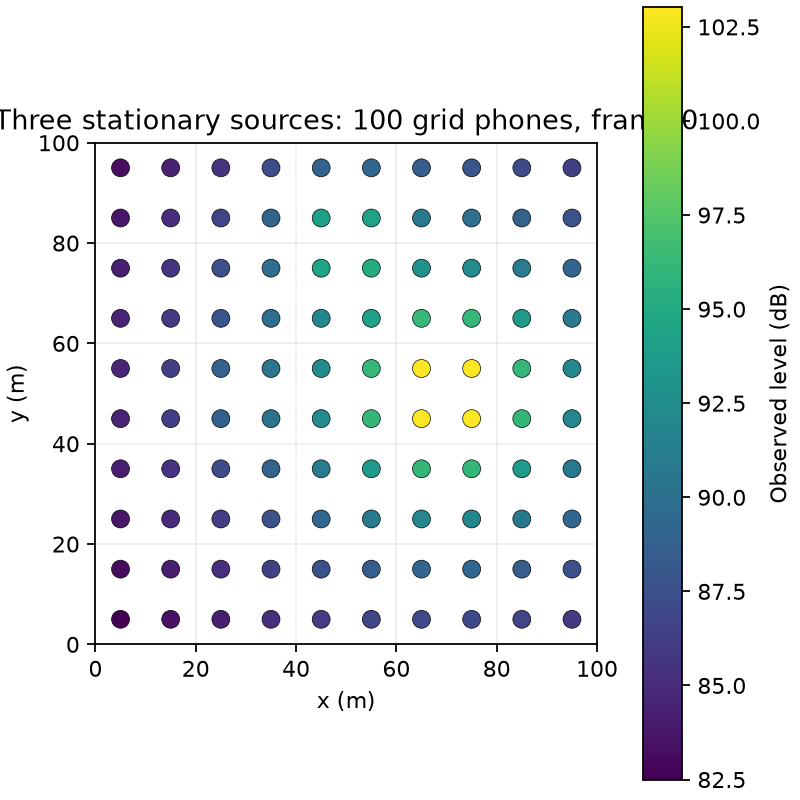

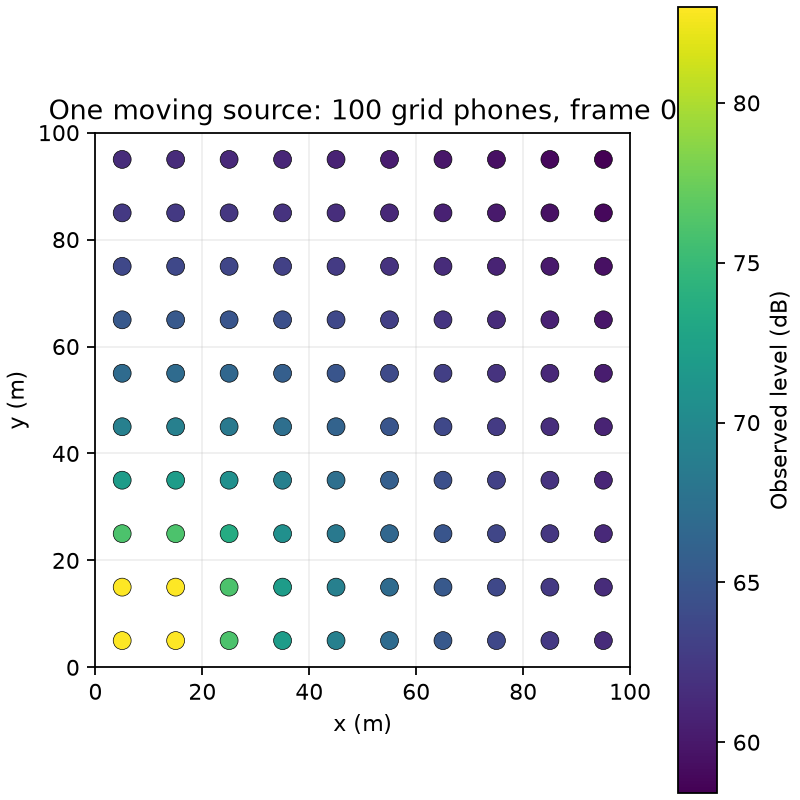

In [5]:
for scene in SCENARIOS:
    figure_path = EVALUATION / f'sampling_100_grid_{scene}.png'
    if not figure_path.is_file():
        raise FileNotFoundError(figure_path)
    display(Image(filename=str(figure_path)))
    print(f'{scene}: 100 grid phones, frame 0')


## 6. True field, GP prediction and error: nine panels

The three rows are the three sound fields. The columns show the true simulated map, GP prediction and absolute error. Every panel uses the **same 100-grid-phone configuration at frame 0**. The true and predicted maps share a colour scale within each row.


Nine panels: 3 sound fields × (truth, GP prediction, absolute error).


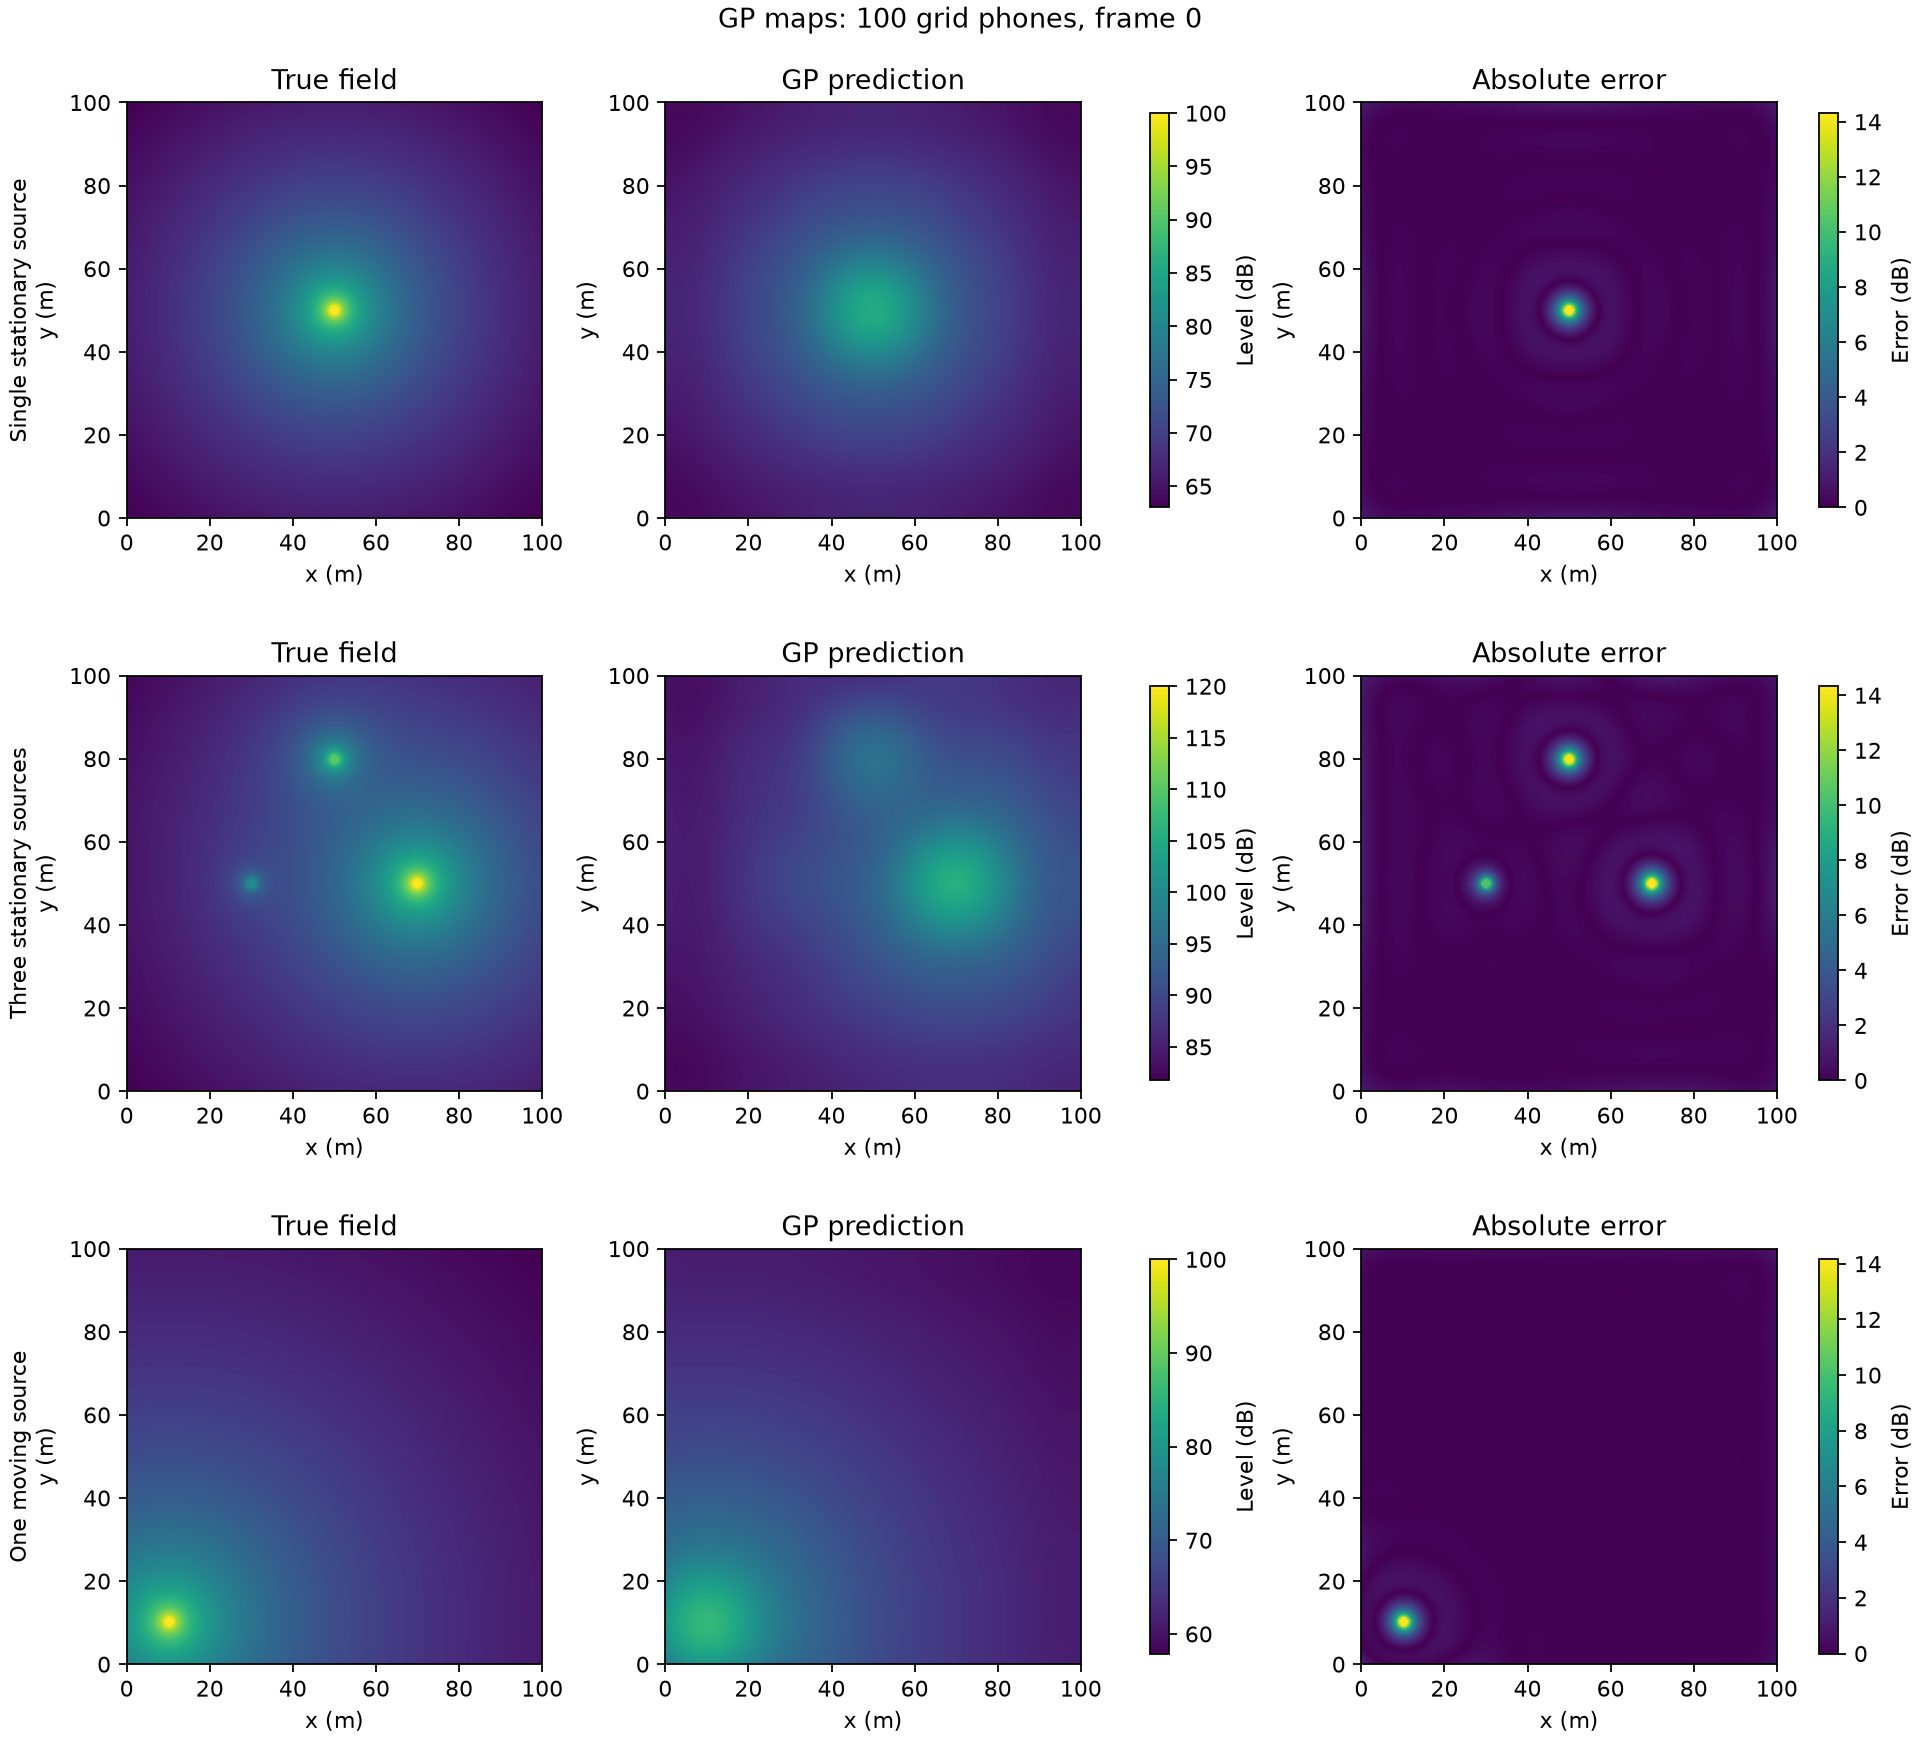

In [6]:
figure_path = EVALUATION / 'gp_truth_prediction_error_3x3.png'
if not figure_path.is_file():
    raise FileNotFoundError(figure_path)
display(Image(filename=str(figure_path)))
print('Nine panels: 3 sound fields × (truth, GP prediction, absolute error).')


## 7. Line chart comparing the three sound fields

Each panel is one sampling layout. Each line is a sound field, with phone count on the horizontal axis and **whole-map GP RMSE** on the vertical axis. This uses all 45 configurations. The moving-source RMSE includes all 101 frames, while each stationary scene has one frame.


The underlying values are in overall_metrics.csv and three_scenario_comparison.csv.


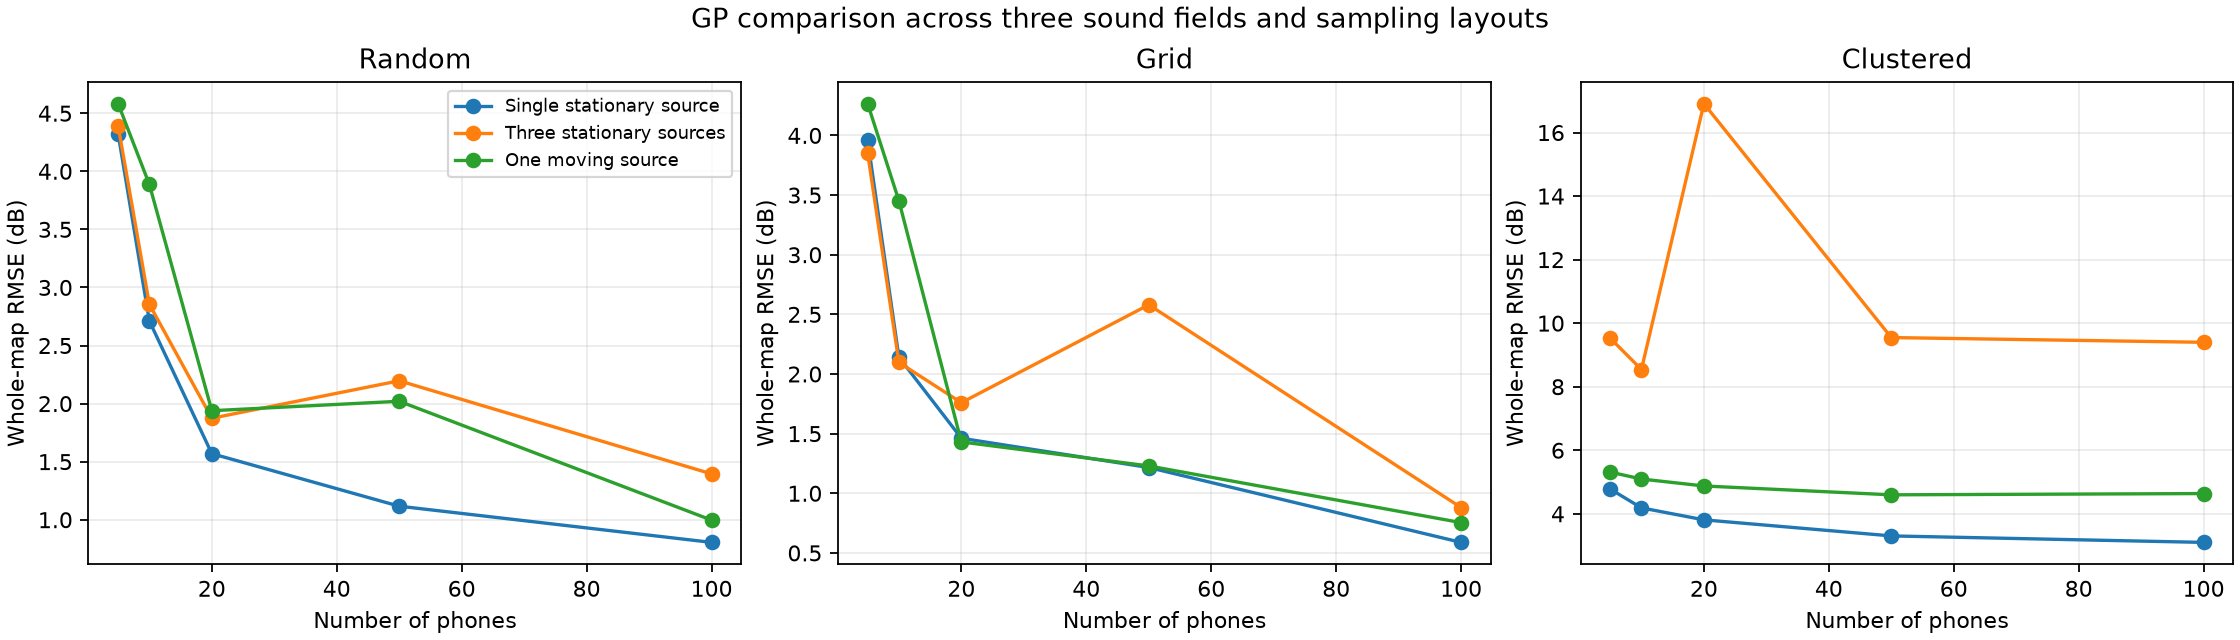

In [7]:
figure_path = EVALUATION / 'gp_three_scenario_rmse_lines.png'
if not figure_path.is_file():
    raise FileNotFoundError(figure_path)
display(Image(filename=str(figure_path)))
print('The underlying values are in overall_metrics.csv and three_scenario_comparison.csv.')


## All saved data and limits

- `model_inputs/`: 45 `.npz` observation arrays (`phone_positions`, `phone_levels`) and three common `query_positions.npy` arrays.
- `gp_predictions/`: 45 GP `.npy` prediction arrays, plus the run manifest and model settings.
- `evaluation_only/`: three `true_levels.npy` arrays, three `source_positions.npy` arrays, complete overall/frame/source score CSV files, the three-scene comparison CSV, and **five** PNG figure files (three sampling maps, one nine-panel comparison, one line chart).

The observations are ideal samples from synthetic maps. The 0.5 dB noise is a GP model assumption, not measured phone noise. The figures show frame 0, while the moving-source numerical scores include all 101 frames. This does not establish real-world dBA accuracy or produce GP uncertainty maps.
